<a href="https://colab.research.google.com/github/nattaponm/Teach_Pysteps_KKN_summerStorm/blob/main/notebooks/06_storm_tracking_tdating.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 6: เซลล์พายุลูกไหนถล่มที่ไหน — กำเนิด อายุ ทิศทาง ขนาด และความแรง
### Thunderstorm Detection and Tracking (T-DaTing) for the 3 May 2024 summer storms

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 1–3 (NB4–5 ช่วยให้เข้าใจดีขึ้น)

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **ตรวจจับเซลล์พายุ** ด้วยวิธี multi-threshold ของ T-DaTing และปรับพารามิเตอร์ให้เหมาะกับเรดาร์ KKN
2. **ติดตามเซลล์ตลอดวัน** และคำนวณ **อายุ ระยะทาง ความเร็ว ทิศทาง ขนาด และความแรง** ของแต่ละเซลล์
3. **วิเคราะห์จุดกำเนิดพายุเทียบกับภูมิประเทศ** และวงจรรายวัน (diurnal cycle)
4. **ระบุว่าเซลล์ใดทำให้เกิดความเสียหาย** และ **ประมาณเวลาเกิดเหตุ** ที่ข่าวระบุเพียง "กลางคืน"
5. **ส่งออกเส้นทางพายุเป็น GeoPackage** สำหรับ GIS

## 📖 1. แนวคิดและสมการ

### 1.1 จาก "ฟิลด์" สู่ "วัตถุ"
NB3–NB5 มองฝนเป็นฟิลด์ต่อเนื่อง แต่นักพยากรณ์และ ปภ. คิดเป็น **"พายุลูกนี้กำลังมุ่งหน้าไปอำเภอนั้น"** — การมองพายุเป็น **วัตถุ (object)** ทำให้วัดคุณสมบัติของพายุแต่ละลูกได้

### 1.2 การตรวจจับแบบ multi-threshold (T-DaTing; Feldmann et al., 2021)
1. หาพื้นที่ที่ $Z \ge$ `minref` (เช่น 33–35 dBZ) และมีขนาด ≥ `minsize` pixel
2. ภายในพื้นที่นั้น เพิ่ม threshold ทีละขั้น (`mindiff`) จนถึง `maxref` เพื่อ **แยกแกนพายุที่อยู่ติดกัน**
3. เก็บเฉพาะเซลล์ที่มีค่าสูงสุด ≥ `minmax` และแกนห่างกัน ≥ `mindis` pixel

### 1.3 การติดตาม (tracking)
เลื่อนเซลล์เวลาก่อนหน้าไปข้างหน้าด้วย motion field (optical flow) แล้วจับคู่กับเซลล์เวลาปัจจุบันที่ **ซ้อนทับกันมากพอ** (`match_frac`)
คุณสมบัติของแต่ละ track:
$$ r_e = \sqrt{A/\pi},\qquad |\mathbf{V}| = \frac{\sum_k \lVert \mathbf{x}_{k+1}-\mathbf{x}_k \rVert}{t_{\mathrm{end}} - t_{\mathrm{start}}},\qquad
   \text{lifetime} = t_{\mathrm{end}} - t_{\mathrm{start}} $$

### 1.4 ทำไมความถี่ของข้อมูลจึงสำคัญ
ใน 15 นาที เซลล์เคลื่อนที่ 6–15 km ซึ่งใกล้เคียงขนาดของเซลล์เอง การจับคู่จึงขาดตอนง่าย → track สั้นกว่าความจริง ผลที่ได้จึงเป็น **ขอบล่าง** ของอายุพายุ

### 1.5 รูปแบบ reflectivity ที่บ่งชี้ลมแรง
- **Bow echo:** แนวพายุโค้งเป็นคันธนู — ลมแรงที่สุดอยู่ตรงยอดโค้ง
- **Rear-inflow notch:** รอยเว้าด้านหลังแนวพายุที่อากาศแห้งไหลเข้า
- แต่ reflectivity 2 km จากเรดาร์ 4 มุมยกบอกได้จำกัด ต้องยืนยันด้วย Doppler (NB3 ส่วนเสริม / repo ที่สอง)

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Pysteps_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 cartopy netCDF4 geopandas cmweather
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "kkn_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.data_io import load_pcappi, time_index
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Pysteps_KKN_summerStorm/data


In [2]:
from pysteps.feature import tstorm
from pysteps.tracking import tdating

Z, meta = load_pcappi(DATA)
ts = meta["timestamps"]
DT = meta["accutime"]
reports = kt.load_reports(DATA, meta)
date0 = ts[0].replace(hour=0, minute=0)
NW = kt.box_around(meta, 102.3, 17.25, 110)

# พารามิเตอร์ที่ปรับสำหรับ pseudo-CAPPI 2 km ของ KKN (ข้อมูลทุก 15 นาที, กริด 1 km)
# ค่าตั้งต้นของ pysteps (minref 35, minsize 50, minmax 41, mindis 10, mintrack 3) ถูกปรับมาสำหรับเรดาร์สวิตเซอร์แลนด์ (ทุก 5 นาที)
PARAMS = dict(minref=33, maxref=45, mindiff=5, minsize=15, minmax=40, mindis=8)
TRACK_KW = dict(mintrack=2, match_frac=0.25)
a, b = time_index(meta, "05:00"), time_index(meta, "17:00")
VIDEO = np.nan_to_num(Z[a:b + 1], nan=-15.0)            # T-DaTing ไม่รับ NaN
TIMES = list(ts[a:b + 1])
print(f"ช่วงเวลาติดตาม: {TIMES[0]:%H:%M}–{TIMES[-1]:%H:%M} UTC ({len(TIMES)} ภาพ) | พารามิเตอร์: {PARAMS}")

Pysteps configuration file found at: /usr/local/lib/python3.12/dist-packages/pysteps/pystepsrc



ช่วงเวลาติดตาม: 05:00–17:00 UTC (49 ภาพ) | พารามิเตอร์: {'minref': 33, 'maxref': 45, 'mindiff': 5, 'minsize': 15, 'minmax': 40, 'mindis': 8}


## 🔍 3. ตรวจจับเซลล์ในภาพเดียว: 09:30 UTC (16:30 น.) เวลาเกิดเหตุที่หนองบัวลำภู

พบ 20 เซลล์ทั่วทั้งรัศมี


บันทึกรูปแล้ว: figures/nb6_detection_0930.png, figures/nb6_detection_0930.pdf


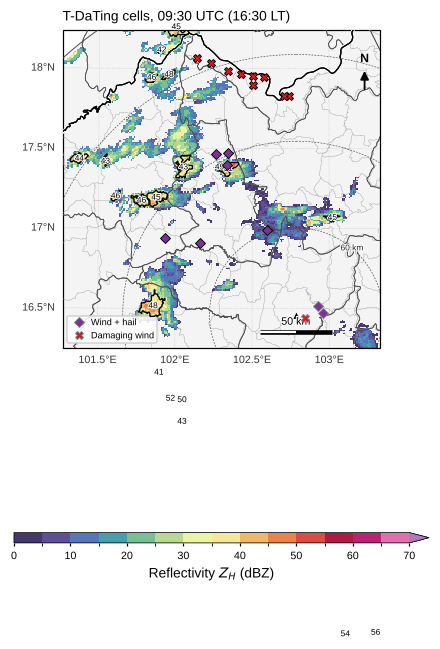

,ID,area_km2,max_dbz
18,19,136,55.5
19,20,75,54.0
16,17,105,52.3
6,7,71,51.4
15,16,22,49.9
8,9,18,49.4
2,3,34,48.5
13,14,171,48.2


In [3]:
i = time_index(meta, "09:30")
cells, labels = tstorm.detection(np.nan_to_num(Z[i], nan=-15.0), time=ts[i], **PARAMS)
print(f"พบ {len(cells)} เซลล์ทั่วทั้งรัศมี")

fig, axs = mp.map_panels(1, 1, meta, panel_width=4.8, zoom=NW)
im = mp.radar_map(axs[0], Z[i], meta, zoom=NW, title=f"T-DaTing cells, {mp.tlabel(ts[i])}")
crs = mp.get_crs(meta)
for _, c in cells.iterrows():
    for x, y in kt.contour_xy(c["cont"], meta):
        axs[0].plot(x, y, color="k", lw=0.9, transform=crs, zorder=6)
    cx, cy = kt.pixel_to_xy(meta, c["cen_x"], c["cen_y"])
    axs[0].text(cx, cy, f"{c['max_ref']:.0f}", transform=crs, fontsize=5.5, ha="center", va="center",
                zorder=7, path_effects=mp.halo(1.2))
mp.add_reports(axs[0], reports)
mp.add_colorbar(fig, im, axs, shrink=0.8)
mp.save_figure(fig, "nb6_detection_0930")
plt.show()
cells.assign(area_km2=cells["area"], max_dbz=cells["max_ref"])[["ID", "area_km2", "max_dbz"]].sort_values("max_dbz", ascending=False).head(8)

## 🧭 4. ติดตามเซลล์ตลอดบ่ายถึงเที่ยงคืน (05:00–17:00 UTC)
⏳ ใช้เวลาประมาณ 30–60 วินาที

In [4]:
tracks, cell_list, label_list = tdating.dating(VIDEO, TIMES, **TRACK_KW, **PARAMS)
TT = kt.track_table(tracks, meta)
TT["start_LT"] = (TT["start_utc"] + pd.Timedelta(hours=7)).dt.strftime("%H:%M")
TT["start_terrain_m"] = mp.terrain_at(meta, TT["start_lon"].values, TT["start_lat"].values)
print(f"จำนวน track: {len(TT)} | อยู่ ≥ 30 นาที: {(TT['lifetime_min'] >= 30).sum()} | อายุสูงสุด {TT['lifetime_min'].max():.0f} นาที")
TT.sort_values("max_dbz", ascending=False).head(10)[
    ["track_id", "start_LT", "lifetime_min", "path_km", "speed_kmh", "direction_to_deg", "max_dbz", "max_area_km2", "start_terrain_m"]
].round(1)

จำนวน track: 114 | อยู่ ≥ 30 นาที: 59 | อายุสูงสุด 120 นาที


,track_id,start_LT,lifetime_min,path_km,speed_kmh,direction_to_deg,max_dbz,max_area_km2,start_terrain_m
52,53,16:15,45.0,11.4,15.1,122.0,55.5,144.0,178.8
51,52,16:15,60.0,18.8,18.8,106.4,54.5,175.0,560.3
48,49,16:00,90.0,40.4,26.9,101.0,54.0,174.0,191.0
90,91,19:45,60.0,41.1,41.1,49.1,54.0,144.0,184.4
12,13,14:00,30.0,18.6,37.2,135.0,53.9,157.0,222.7
4,5,13:00,90.0,14.5,9.7,18.4,53.5,76.0,218.7
13,14,14:00,45.0,28.9,38.5,95.4,53.4,246.0,176.7
25,26,14:45,15.0,6.4,25.6,231.3,52.9,62.0,207.7
27,28,15:00,15.0,6.1,24.3,80.5,52.8,37.0,185.0
3,4,13:00,60.0,31.1,31.1,93.7,52.6,89.0,221.0


### แผนที่เส้นทางพายุบนภูมิประเทศ พร้อมจุดรายงานความเสียหาย
สีของเส้น = เวลาที่เซลล์เริ่มก่อตัว (เวลาไทย), วงกลม = จุดเริ่ม

บันทึกรูปแล้ว: figures/nb6_tracks_map.png, figures/nb6_tracks_map.pdf


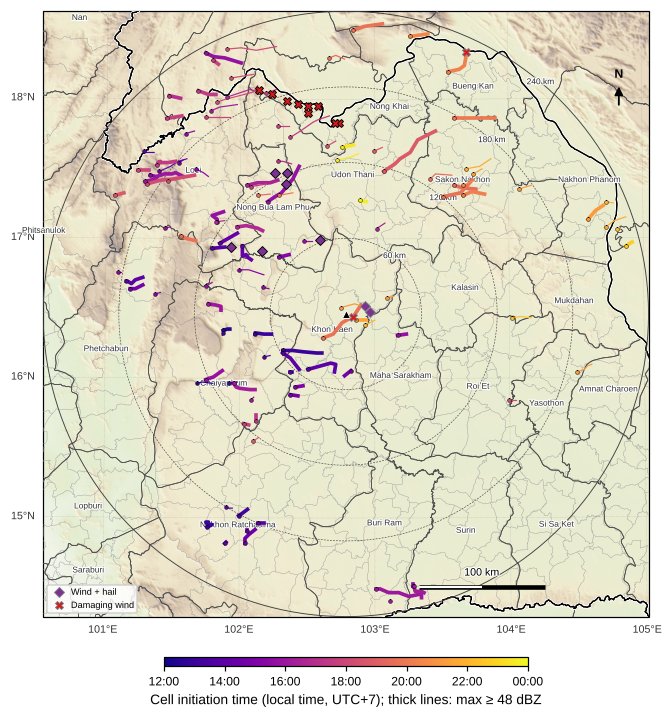

In [5]:
fig, axs = mp.map_panels(1, 1, meta, panel_width=6.0)
ax = axs[0]
ax.set_extent(mp.extent_of(meta), crs=crs)
mp.add_terrain(ax, meta, alpha=0.75)
mp.add_basemap(ax, meta, province_labels=True)
cmap = plt.matplotlib.colormaps["plasma"]
t0n, t1n = TIMES[0], TIMES[-1]
for tr, (_, row) in zip(tracks, TT.iterrows()):
    if row["n_frames"] < 2:
        continue
    x, y = kt.pixel_to_xy(meta, tr.cen_x.values, tr.cen_y.values)
    f = (row["start_utc"] - t0n) / (t1n - t0n)
    lw = 0.8 + 1.6 * (row["max_dbz"] >= 48)
    ax.plot(x, y, color=cmap(f), lw=lw, transform=crs, zorder=7)
    ax.plot(x[0], y[0], "o", ms=2.5, color=cmap(f), mec="k", mew=0.3, transform=crs, zorder=8)
mp.add_reports(ax, reports)
sm = plt.matplotlib.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, (t1n - t0n).total_seconds() / 3600))
cb = fig.colorbar(sm, ax=ax, orientation="horizontal", shrink=0.6, pad=0.03, aspect=40)
cb.set_ticks(np.arange(0, 13, 2))
cb.set_ticklabels([f"{(12 + h) % 24:02d}:00" for h in range(0, 13, 2)])
cb.set_label("Cell initiation time (local time, UTC+7); thick lines: max ≥ 48 dBZ")
mp.add_scalebar(ax)
mp.add_north_arrow(ax)
mp.save_figure(fig, "nb6_tracks_map")
plt.show()

## 📊 5. สถิติของเซลล์: วงจรรายวัน ทิศทาง และอายุ

บันทึกรูปแล้ว: figures/nb6_cell_statistics.png, figures/nb6_cell_statistics.pdf


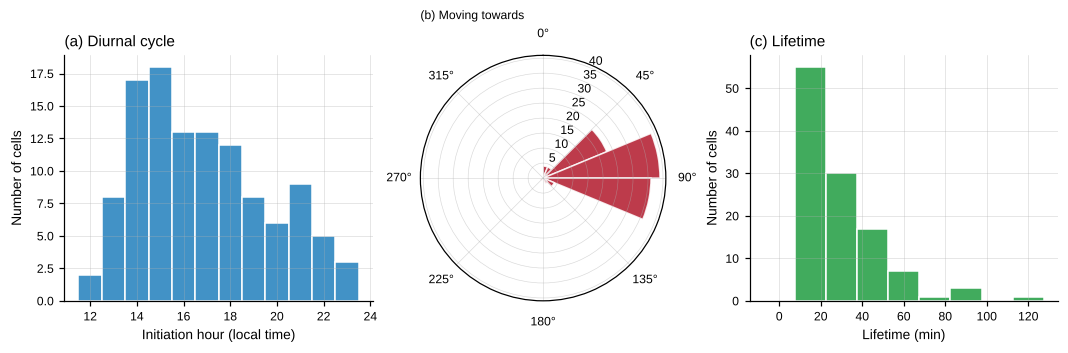

In [6]:
fig = plt.figure(figsize=(9.6, 3.1), layout="constrained")
ax1 = fig.add_subplot(1, 3, 1)
hours = (TT["start_utc"].dt.hour + 7) % 24
ax1.hist(hours, bins=np.arange(12, 25) - 0.5, color="#4292c6", edgecolor="w")
ax1.set_xticks(range(12, 25, 2))
mp.skill_axes(ax1, xlabel="Initiation hour (local time)", ylabel="Number of cells", title="(a) Diurnal cycle")
ax2 = fig.add_subplot(1, 3, 2, projection="polar")
d = np.radians(TT.loc[TT["lifetime_min"] >= 15, "direction_to_deg"].dropna())
counts, edges = np.histogram(d, bins=np.radians(np.arange(0, 361, 22.5)))
ax2.bar(edges[:-1], counts, width=np.radians(22.5), align="edge", color="#b2182b", edgecolor="w", alpha=0.85)
ax2.set_theta_zero_location("N")
ax2.set_theta_direction(-1)
ax2.set_title("(b) Moving towards", loc="left", fontsize=8)
ax3 = fig.add_subplot(1, 3, 3)
ax3.hist(TT["lifetime_min"], bins=np.arange(0, 136, 15) - 7.5, color="#41ab5d", edgecolor="w")
mp.skill_axes(ax3, xlabel="Lifetime (min)", ylabel="Number of cells", title="(c) Lifetime")
mp.save_figure(fig, "nb6_cell_statistics")
plt.show()

## ⛰️ 6. พายุเกิดบนที่สูงมากกว่าหรือไม่?
เทียบ **ความสูงภูมิประเทศ ณ จุดเริ่มต้นของเซลล์** กับ **ความสูงของพื้นที่ทั้งหมดในรัศมีเรดาร์**

บันทึกรูปแล้ว: figures/nb6_initiation_terrain.png, figures/nb6_initiation_terrain.pdf


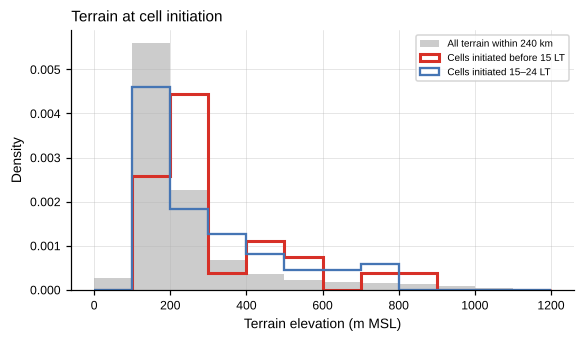

ความสูงมัธยฐาน: ทั้งพื้นที่ 185 m | เซลล์ก่อน 15:00 น. 226 m | เซลล์หลัง 15:00 น. 209 m


In [7]:
import xarray as xr
with xr.open_dataset(os.path.join(DATA, "basemap", "terrain_KKN_aeqd_600m.nc")) as ds:
    X_, Y_ = np.meshgrid(ds["x"].values, ds["y"].values)
    elev_all = ds["elevation"].values[np.hypot(X_, Y_) <= 240e3]
early = TT["start_utc"] < date0.replace(hour=8)          # เซลล์ที่เกิดก่อน 15:00 น.
fig, ax = plt.subplots(figsize=(5.2, 3), layout="constrained")
bins = np.arange(0, 1300, 100)
ax.hist(elev_all, bins=bins, density=True, color="0.8", label="All terrain within 240 km")
ax.hist(TT.loc[early, "start_terrain_m"], bins=bins, density=True, histtype="step", lw=2, color="#d73027",
        label="Cells initiated before 15 LT")
ax.hist(TT.loc[~early, "start_terrain_m"], bins=bins, density=True, histtype="step", lw=1.5, color="#4575b4",
        label="Cells initiated 15–24 LT")
mp.skill_axes(ax, xlabel="Terrain elevation (m MSL)", ylabel="Density", title="Terrain at cell initiation")
ax.legend(fontsize=6.5)
mp.save_figure(fig, "nb6_initiation_terrain")
plt.show()
print(f"ความสูงมัธยฐาน: ทั้งพื้นที่ {np.median(elev_all):.0f} m | เซลล์ก่อน 15:00 น. {TT.loc[early, 'start_terrain_m'].median():.0f} m "
      f"| เซลล์หลัง 15:00 น. {TT.loc[~early, 'start_terrain_m'].median():.0f} m")

## 📍 7. เซลล์ใดผ่านจุดที่เกิดความเสียหาย?

In [8]:
rows = []
for name in kt.KEY_SITES:
    r = kt.site(reports, name)
    near = kt.tracks_near_point(tracks, meta, r["lon"], r["lat"], radius_km=15)
    if near.empty:
        rows.append({"site": name, "report_LT": r["time_LT"] if isinstance(r["time_LT"], str) else "night"})
        continue
    t_rep = kt.report_time_utc(r, date0)
    if t_rep is not None:                       # มีเวลารายงาน → เลือก track ที่ผ่านใกล้เวลานั้นที่สุด
        best = near.iloc[(near["closest_utc"] - pd.Timestamp(t_rep)).abs().argsort().iloc[0]]
    else:                                       # รายงานแค่ "กลางคืน" → เลือก track ที่แรงที่สุด
        best = near.sort_values("max_dbz_at_closest", ascending=False).iloc[0]
    rows.append({"site": name, "report_LT": r["time_LT"] if isinstance(r["time_LT"], str) else "night",
                 "track_id": int(best["track_id"]), "closest_LT": (best["closest_utc"] + pd.Timedelta(hours=7)).strftime("%H:%M"),
                 "distance_km": best["distance_km"], "max_dbz_at_closest": best["max_dbz_at_closest"]})
HIT = pd.DataFrame(rows)
HIT.round(1)

,site,report_LT,track_id,closest_LT,distance_km,max_dbz_at_closest
0,Phu Kradueng,14:00,9,14:00,5.3,47.0
1,Na Klang,16:30,39,16:30,2.4,51.4
2,Suwannakhuha,16:30,39,16:45,7.0,51.7
3,Si Chiang Mai,17:00,64,18:00,8.1,46.0
4,Bueng Kan,night,94,21:00,0.7,46.0
5,Khon Kaen city,night,104,21:30,3.5,48.5


บันทึกรูปแล้ว: figures/nb6_naklang_cell_lifecycle.png, figures/nb6_naklang_cell_lifecycle.pdf


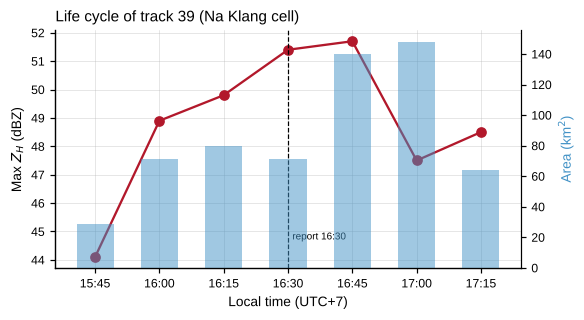

In [9]:
tid = int(HIT.loc[HIT["site"] == "Na Klang", "track_id"].iloc[0])
tr = tracks[tid - 1]
fig, ax = plt.subplots(figsize=(5.2, 2.8), layout="constrained")
t_lt = pd.to_datetime(tr.time.values) + pd.Timedelta(hours=7)
ax.plot(t_lt, tr.max_ref, "o-", color="#b2182b", label="max $Z_H$")
ax2 = ax.twinx()
ax2.bar(t_lt, tr.area, width=0.006, color="#4292c6", alpha=0.5, label="area")
ax2.set_ylabel("Area (km$^2$)", color="#4292c6")
ax2.spines["right"].set_visible(True)
ax.axvline(pd.Timestamp(date0.replace(hour=16, minute=30)), color="k", ls="--", lw=0.8)
ax.text(pd.Timestamp(date0.replace(hour=16, minute=31)), ax.get_ylim()[0] + 1, "report 16:30", fontsize=6.5)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
mp.skill_axes(ax, xlabel="Local time (UTC+7)", ylabel="Max $Z_H$ (dBZ)", title=f"Life cycle of track {tid} (Na Klang cell)")
mp.save_figure(fig, "nb6_naklang_cell_lifecycle")
plt.show()

## ⏱️ 8. ติดตามด้วยข้อมูลที่ interpolate เป็น 5 นาที (08:00–11:00 UTC บริเวณหนองบัวลำภู)

In [10]:
Zc, mc = kt.crop(Z, meta, NW)
iA, iB = time_index(meta, "08:00"), time_index(meta, "11:00")
Z5, ts5, _ = kt.advection_interpolate(Zc[iA:iB + 1], dict(mc, timestamps=ts[iA:iB + 1]), n_sub=3)
res = {}
for lab, vid, tl in [("15 min", Zc[iA:iB + 1], list(ts[iA:iB + 1])), ("5 min (interpolated)", Z5, list(ts5))]:
    trk, _, _ = tdating.dating(np.nan_to_num(vid, nan=-15.0), tl, **TRACK_KW, **PARAMS)
    t_ = kt.track_table(trk, mc)
    res[lab] = {"n_tracks": len(t_), "median_lifetime_min": t_["lifetime_min"].median(),
                "max_lifetime_min": t_["lifetime_min"].max(), "tracks ≥ 45 min": int((t_["lifetime_min"] >= 45).sum())}
pd.DataFrame(res).T

,n_tracks,median_lifetime_min,max_lifetime_min,tracks ≥ 45 min
15 min,29.0,15.0,120.0,6.0
5 min (interpolated),52.0,20.0,95.0,11.0


ข้อมูล 5 นาทีที่ interpolate ทำให้ **track ยาวและต่อเนื่องขึ้น** เพราะเซลล์เคลื่อนที่น้อยลงระหว่างภาพ จับคู่ได้ง่ายขึ้น
แต่ระวัง: interpolation ไม่ได้สร้างข้อมูลใหม่ อายุที่ยาวขึ้นบางส่วนมาจากการ "เชื่อม" เซลล์ที่จริง ๆ แล้วอาจเป็นคนละลูก

## 💾 9. ส่งออกเส้นทางพายุเป็น GeoPackage และ CSV (เปิดใน QGIS)

In [11]:
os.makedirs("output", exist_ok=True)
pts, lines = kt.tracks_to_gdf(tracks, meta, to_wgs84=True)
gpkg = "output/KKN_20240503_storm_tracks.gpkg"
pts.to_file(gpkg, layer="cell_centroids", driver="GPKG")
lines.to_file(gpkg, layer="tracks", driver="GPKG")
TT.to_csv("output/KKN_20240503_track_table.csv", index=False)
print(f"บันทึก {gpkg}: {len(pts)} จุด, {len(lines)} เส้น | และ output/KKN_20240503_track_table.csv")

บันทึก output/KKN_20240503_storm_tracks.gpkg: 339 จุด, 114 เส้น | และ output/KKN_20240503_track_table.csv


---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 6.1: พารามิเตอร์ `minref` มีผลแค่ไหน?
รัน T-DaTing **เฉพาะบริเวณหนองบัวลำภู (`Zc`, `mc`) ช่วง 07:00–11:00 UTC** ด้วย `minref` = 30, 33, 36, 40 (พารามิเตอร์อื่นเหมือน `PARAMS`) และอีกครั้งด้วย **ค่าตั้งต้นของ pysteps** (`tdating.dating(video, times)` โดยไม่ใส่พารามิเตอร์)
สร้างตาราง: จำนวน track, อายุมัธยฐาน, อายุสูงสุด และ dBZ สูงสุดเฉลี่ย

**คำถาม:** ถ้า `minref` ต่ำเกินไปหรือสูงเกินไปจะเกิดอะไรขึ้น? ทำไมค่าตั้งต้นของ pysteps จึงเจอเซลล์น้อยในข้อมูลของเรา?

<details>
<summary><b>💡 คำใบ้ (คลิกเพื่อเปิด)</b></summary>

- `i7, i11 = time_index(meta, "07:00"), time_index(meta, "11:00")` แล้ว `vid = np.nan_to_num(Zc[i7:i11 + 1], nan=-15.0)`
- `p = dict(PARAMS, minref=m)` แล้ว `trk, _, _ = tdating.dating(vid, list(ts[i7:i11 + 1]), **TRACK_KW, **p)`
- `t_ = kt.track_table(trk, mc)`

</details>

In [12]:
# ✍️ แบบฝึกหัด 6.1 — เขียนโค้ดของคุณที่นี่ (ลบ # หน้าบรรทัดแล้วเติมส่วนที่เป็น ...)
# i7, i11 = time_index(meta, "07:00"), time_index(meta, "11:00")
# vid = np.nan_to_num(Zc[i7:i11 + 1], nan=-15.0)
# rows = []
# for m in [30, 33, 36, 40]:
#     ...

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 6.1 (ลองทำเองก่อน! ดับเบิลคลิกเพื่อดูโค้ด แล้วกด ▶ เพื่อรัน)
i7, i11 = time_index(meta, "07:00"), time_index(meta, "11:00")
vid, tl = np.nan_to_num(Zc[i7:i11 + 1], nan=-15.0), list(ts[i7:i11 + 1])
rows = []
for m in [30, 33, 36, 40]:
    trk, _, _ = tdating.dating(vid, tl, **TRACK_KW, **dict(PARAMS, minref=m))
    t_ = kt.track_table(trk, mc)
    rows.append({"setting": f"minref = {m}", "n_tracks": len(t_), "median_life_min": t_["lifetime_min"].median(),
                 "max_life_min": t_["lifetime_min"].max(), "mean_max_dbz": t_["max_dbz"].mean()})
trk, _, _ = tdating.dating(vid, tl)
t_ = kt.track_table(trk, mc)
rows.append({"setting": "pysteps default", "n_tracks": len(t_),
             "median_life_min": t_["lifetime_min"].median() if len(t_) else np.nan,
             "max_life_min": t_["lifetime_min"].max() if len(t_) else np.nan,
             "mean_max_dbz": t_["max_dbz"].mean() if len(t_) else np.nan})
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\n→ minref ต่ำ: รวมฝนอ่อนเข้ามา เซลล์ใหญ่และเชื่อมกัน | minref สูง: เหลือแต่แกนแรง เซลล์เล็กและหายไปเร็ว"
      "\n  ค่าตั้งต้นต้องการเซลล์ ≥ 50 pixel และอยู่ ≥ 3 ภาพ ซึ่งยากสำหรับเซลล์เล็กอายุสั้นในข้อมูลทุก 15 นาที")

        setting  n_tracks  median_life_min  max_life_min  mean_max_dbz
    minref = 30        35             30.0         120.0          47.2
    minref = 33        35             15.0         120.0          47.5
    minref = 36        30             15.0          90.0          47.6
    minref = 40        12             15.0          30.0          48.7
pysteps default         4             37.5          45.0          48.4

→ minref ต่ำ: รวมฝนอ่อนเข้ามา เซลล์ใหญ่และเชื่อมกัน | minref สูง: เหลือแต่แกนแรง เซลล์เล็กและหายไปเร็ว
  ค่าตั้งต้นต้องการเซลล์ ≥ 50 pixel และอยู่ ≥ 3 ภาพ ซึ่งยากสำหรับเซลล์เล็กอายุสั้นในข้อมูลทุก 15 นาที


### 🧪 แบบฝึกหัด 6.2: เซลล์ที่ถล่มนากลางมาจากไหน?
ใช้ตาราง `HIT` และ `TT` หาเซลล์ที่ผ่านนากลาง แล้วตอบ:
1. เซลล์เริ่มก่อตัว **เวลาใด ที่ไหน (lon/lat) บนภูมิประเทศสูงเท่าไร** และห่างจากนากลางกี่ km
2. **อายุ ระยะทาง ความเร็ว และทิศทาง** ของเซลล์
3. เซลล์นี้ **เกี่ยวข้องกับเซลล์ที่ภูกระดึง** หรือไม่? (ดูระยะห่างและเวลาระหว่างจุดสิ้นสุดของเซลล์ภูกระดึงกับจุดเริ่มต้นของเซลล์นากลาง)

**คำถาม:** ผลนี้สนับสนุนแนวคิด "propagation" ใน NB3 หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `TT.loc[TT["track_id"] == tid]` สำหรับ tid ของนากลางและของภูกระดึง (จาก `HIT`)
- จุดสิ้นสุดของ track: `kt.pixel_to_xy(meta, tracks[tid - 1].cen_x.values[-1], tracks[tid - 1].cen_y.values[-1])`

</details>

In [14]:
# ✍️ แบบฝึกหัด 6.2 — เขียนโค้ดของคุณที่นี่

In [15]:
#@title ✅ เฉลยแบบฝึกหัด 6.2
t_nk = int(HIT.loc[HIT["site"] == "Na Klang", "track_id"].iloc[0])
t_pk = int(HIT.loc[HIT["site"] == "Phu Kradueng", "track_id"].iloc[0])
info = TT.set_index("track_id").loc[[t_pk, t_nk], ["start_LT", "start_lon", "start_lat", "start_terrain_m",
                                                  "lifetime_min", "path_km", "speed_kmh", "direction_to_deg", "max_dbz"]]
info.index = [f"Phu Kradueng cell ({t_pk})", f"Na Klang cell ({t_nk})"]
print(info.round(2).T.to_string())
r = kt.site(reports, "Na Klang")
xs, ys = kt.lonlat_to_xy(meta, info.iloc[1]["start_lon"], info.iloc[1]["start_lat"])
print(f"\nจุดเริ่มเซลล์นากลางห่างจากนากลาง {np.hypot(xs - r['x'], ys - r['y'])/1000:.0f} km")
trp = tracks[t_pk - 1]
xe, ye = kt.pixel_to_xy(meta, trp.cen_x.values[-1], trp.cen_y.values[-1])
gap_t = (pd.Timestamp(tracks[t_nk - 1].time.iloc[0]) - pd.Timestamp(trp.time.iloc[-1])).total_seconds() / 60
print(f"จุดสิ้นสุดเซลล์ภูกระดึง → จุดเริ่มเซลล์นากลาง: {np.hypot(xs - xe, ys - ye)/1000:.0f} km, ห่างกัน {gap_t:.0f} นาที")
print("→ เป็นคนละเซลล์ที่เกิดห่างกันหลายสิบ km และหลายสิบนาที: เซลล์ใหม่เกิดทางตะวันออก/ตะวันออกเฉียงเหนือของบริเวณเดิม"
      "\n  สอดคล้องกับ propagation (NB3) — กลุ่มพายุ 'เคลื่อน' ด้วยการเกิดเซลล์ใหม่ ไม่ใช่ลูกเดิมเดินทางไป")

                 Phu Kradueng cell (9) Na Klang cell (39)
start_LT                         13:45              15:45
start_lon                       101.79              102.2
start_lat                        16.93              17.27
start_terrain_m                 859.67              244.0
lifetime_min                      15.0               90.0
path_km                          10.05              38.44
speed_kmh                         40.2              25.62
direction_to_deg                 84.29              41.76
max_dbz                           50.9               51.7

จุดเริ่มเซลล์นากลางห่างจากนากลาง 20 km
จุดสิ้นสุดเซลล์ภูกระดึง → จุดเริ่มเซลล์นากลาง: 50 km, ห่างกัน 105 นาที
→ เป็นคนละเซลล์ที่เกิดห่างกันหลายสิบ km และหลายสิบนาที: เซลล์ใหม่เกิดทางตะวันออก/ตะวันออกเฉียงเหนือของบริเวณเดิม
  สอดคล้องกับ propagation (NB3) — กลุ่มพายุ 'เคลื่อน' ด้วยการเกิดเซลล์ใหม่ ไม่ใช่ลูกเดิมเดินทางไป


### 🧪 แบบฝึกหัด 6.3: พายุถล่มบึงกาฬและ อ.เมืองขอนแก่น "กลางคืน" กี่โมง?
ข่าวระบุเพียง "คืนวันที่ 3 พ.ค." ใช้ข้อมูลเรดาร์ประมาณเวลา:
1. หา **ช่วงเวลาที่ค่าสูงสุดในรัศมี 10 km ≥ 40 dBZ** ที่จุด `Bueng Kan` และ `Khon Kaen city` (และจุด id 18, 19 ของขอนแก่น)
2. หา **track** ที่ผ่านใกล้ที่สุดและเวลาที่ผ่าน (จาก `HIT`)
3. สรุปเวลาโดยประมาณเป็น **เวลาไทย**

**คำถาม:** ความไม่แน่นอนของเวลาที่ได้มีกี่นาที? ข้อจำกัดอะไรของเรดาร์ที่ต้องระวังสำหรับบึงกาฬ (~230 km) และขอนแก่น (~6 km)?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `s = kt.point_series(Z, meta, r["lon"], r["lat"], 10)` แล้วเลือก `[ts[k] for k in np.where(s >= 40)[0] if ts[k].hour >= 10]`
- แปลงเป็นเวลาไทยด้วย `kt.hhmm(t, local=True)`

</details>

In [16]:
# ✍️ แบบฝึกหัด 6.3 — เขียนโค้ดของคุณที่นี่

In [17]:
#@title ✅ เฉลยแบบฝึกหัด 6.3
rows = []
for rid in [16, 17, 18, 19]:
    r = reports.loc[reports["id"] == rid].iloc[0]
    s = kt.point_series(Z, meta, r["lon"], r["lat"], 10)
    hit_t = [ts[k] for k in np.where(np.nan_to_num(s, nan=-99) >= 40)[0] if 10 <= ts[k].hour <= 18]
    near = kt.tracks_near_point(tracks, meta, r["lon"], r["lat"], 15)
    rows.append({"id": rid, "place": f"{r['district']} / {r['subdistrict']}", "range_km": r["range_km"],
                 "≥40 dBZ (LT)": f"{kt.hhmm(hit_t[0], True)}–{kt.hhmm(hit_t[-1], True)}" if hit_t else "-",
                 "peak dBZ": np.nanmax(s[time_index(meta, "10:00"):]),
                 "nearest track (LT)": ", ".join((t + pd.Timedelta(hours=7)).strftime("%H:%M") for t in near["closest_utc"])})
res63 = pd.DataFrame(rows)
print(res63.round(1).to_string(index=False))
bk, kk = res63.iloc[0], res63.iloc[1]
print(f"\n→ บึงกาฬ: พายุแรง (≥ 40 dBZ) ช่วง {bk['≥40 dBZ (LT)']} น. | อ.เมืองขอนแก่น: ช่วง {kk['≥40 dBZ (LT)']} น. โดยมีเซลล์ผ่านใกล้ที่สุด {kk['nearest track (LT)']}"
      "\n  ความไม่แน่นอนอย่างน้อย ±15 นาที (ช่วงสแกน) — ข่าวที่ว่า 'กลางคืน' จึงน่าจะหมายถึงราว 20:00–22:00 น."
      "\n  บึงกาฬไกล ~230 km ลำคลื่นสูง ~5 km อาจเห็นแค่ส่วนบนของพายุ; ขอนแก่นใกล้มาก ข้อมูลมาจากลำคลื่นต่ำ ~0.3 km และเหนือขึ้นไปเป็น 'กรวยบอด'")

 id                         place  range_km ≥40 dBZ (LT)  peak dBZ         nearest track (LT)
 16         Bueng Kan / Bueng Kan     228.4  20:45–21:00      46.0                      21:00
 17 Mueang Khon Kaen / Nai Mueang       6.3  19:15–22:00      50.5 20:30, 21:15, 21:30, 22:00
 18    Mueang Khon Kaen / Khok Si      18.9  20:30–22:15      51.0 20:45, 21:30, 21:45, 22:15
 19   Mueang Khon Kaen / Nong Tum      16.5  19:15–22:00      51.0 20:45, 21:30, 21:45, 22:15

→ บึงกาฬ: พายุแรง (≥ 40 dBZ) ช่วง 20:45–21:00 น. | อ.เมืองขอนแก่น: ช่วง 19:15–22:00 น. โดยมีเซลล์ผ่านใกล้ที่สุด 20:30, 21:15, 21:30, 22:00
  ความไม่แน่นอนอย่างน้อย ±15 นาที (ช่วงสแกน) — ข่าวที่ว่า 'กลางคืน' จึงน่าจะหมายถึงราว 20:00–22:00 น.
  บึงกาฬไกล ~230 km ลำคลื่นสูง ~5 km อาจเห็นแค่ส่วนบนของพายุ; ขอนแก่นใกล้มาก ข้อมูลมาจากลำคลื่นต่ำ ~0.3 km และเหนือขึ้นไปเป็น 'กรวยบอด'


---
## 📝 สรุป
- T-DaTing แปลงฟิลด์ reflectivity เป็น **วัตถุพายุ** ที่วัด **อายุ ระยะทาง ความเร็ว ทิศทาง ขนาด และความแรง** ได้ — ต้อง **ปรับพารามิเตอร์** ให้เหมาะกับเรดาร์และความถี่ข้อมูล
- เซลล์ส่วนใหญ่ **อายุสั้น (15–45 นาที)** และ **เคลื่อนไปทางตะวันออก–ตะวันออกเฉียงเหนือ** สอดคล้องกับ NB3
- จุดกำเนิดเซลล์ช่วงบ่ายต้น ๆ อยู่บนพื้นที่ **สูงกว่าพื้นที่โดยรวมเล็กน้อย** (มัธยฐาน ~226 m เทียบกับ ~185 m) และเซลล์แรกของวันเกิดบนที่สูง ~900 m ทางตะวันตก (NB1) ส่วนเซลล์ตอนค่ำเกิดบนที่ราบมากขึ้น (ตามแนว outflow) — ต้องใช้หลายวันจึงจะสรุปได้
- เรดาร์ช่วย **ยืนยันและเติมเวลาเกิดเหตุ** ที่ข่าวระบุไม่ชัด เช่น บึงกาฬราว 20:45–21:00 น. และ อ.เมืองขอนแก่นช่วงประมาณ 19:15–22:00 น.
- เส้นทางพายุส่งออกเป็น **GeoPackage** ใช้ต่อใน GIS ได้ เช่น ซ้อนกับแผนที่หมู่บ้าน/ประชากร เพื่อประเมินความเสี่ยง

### ❓ คำถามชวนคิด / โครงงานต่อยอด
1. ถ้าทำซ้ำกับ **วันพายุฤดูร้อนหลายวัน** (มี.ค.–พ.ค.) จะสร้าง "แผนที่จุดกำเนิดพายุ" ของอีสานได้หรือไม่? ควรใช้ข้อมูลกี่ปี?
2. จุดกำเนิดพายุสัมพันธ์กับ **ภูมิประเทศ การใช้ที่ดิน (ป่า–นาข้าว–เมือง) หรือแหล่งน้ำ** อย่างไร? ใช้ข้อมูลภูมิสารสนเทศอะไรได้บ้าง?
3. จะใช้ **Doppler และ dual-polarization** (repo ที่สอง) ยืนยันว่าเซลล์ที่นากลางมีลูกเห็บและ downburst ได้อย่างไร?
4. (ป.โท) สร้าง **cell-based nowcast**: เลื่อน contour ของเซลล์ตามความเร็วล่าสุด 30 นาที แล้วเทียบกับ extrapolation ใน NB4

### 🎓 จบหลักสูตร!
นิสิตได้เดินทางครบ: **สภาพแวดล้อม → ความแรงและลูกเห็บ → การเคลื่อนที่ → nowcast แบบ deterministic → แบบความน่าจะเป็น → วัตถุพายุ** ของพายุฤดูร้อนจริงในภาคอีสาน

### 📚 เอกสารอ้างอิง
- Feldmann, M., Germann, U., Gabella, M., & Berne, A. (2021). A characterisation of Alpine mesocyclone occurrence. *Weather Clim. Dynam.*, 2, 1225–1244. (T-DaTing)
- Dixon, M., & Wiener, G. (1993). TITAN: Thunderstorm Identification, Tracking, Analysis, and Nowcasting — A radar-based methodology. *J. Atmos. Oceanic Technol.*, 10, 785–797.
- Fujita, T. T. (1978). *Manual of Downburst Identification for Project NIMROD*. SMRP Research Paper 156, University of Chicago.
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.